<!-- ISM4543-BANNER -->
# Integrative Assignment on Week 05 Material — QuickLend Financial
## Logistic regression for credit risk

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, September 28, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

> **Why "integrative"?** This assignment does not test this week's technique in
> isolation. It expects you to bring forward the data preparation, evaluation, and
> communication skills from earlier weeks and combine them with what you learned
> this week. Marks are lost for a technically correct model presented without
> framing, verification, or interpretation.

---


## The client: QuickLend Financial

**QuickLend Financial** is an online lender that approves or declines small personal loans in
minutes. Over the past two years it has issued **2,000 loans**, and it knows how each one turned
out: repaid, or defaulted. Today's approve-or-decline rule is a **credit-score cutoff** inherited
from a previous head of risk, and nobody remembers how the cutoff was chosen. Last year it was
lowered by twenty points to grow the book; volume rose, and so did losses, and nobody has separated
the two effects. Three people want answers from those 2,000 loans.

- **David Kim, Chief Risk Officer:** *"Our default rate is climbing. I want a model that flags
  high-risk applications before we approve them, so we can decline them or ask for collateral. Each
  default costs us about \$15,000 in lost principal and collection costs."*
- **Priya Sharma, VP of Lending:** *"But we can't be too conservative. Every good loan we turn away
  is lost revenue, about \$3,000 in interest over the life of the loan. We need to balance risk with
  growth, and I won't sign off on a model that just rejects everybody."*
- **Tom Nguyen, CEO:** *"The board wants to understand the risk model, not just trust a black box.
  Show me which factors drive default, and how much each one matters."*

The decision the model feeds is made **at application time**, on every application: approve,
decline, or require collateral. A model that estimates each applicant's probability of default is
half the job. The other half is choosing **where to set the threshold** that turns that probability
into a decision, and that choice comes from what each kind of mistake costs, not from habit.


### The questions you will answer

| # | Question | Asked by | Worked out in | Answered in |
|---|---|---|---|---|
| 1 | What does each kind of mistake cost QuickLend, and which metric follows from those costs? | David and Priya | Part 1 | 1.2, 1.3 |
| 2 | How common is default, and which applicant features separate the defaulters from the rest? | David | Part 2 | 2.2 |
| 3 | At the default 0.5 cutoff, what does the model get right and wrong, in loans and in dollars? | David | Parts 3 to 5 | 4.1, 4.2, 5.1 |
| 4 | Precision or recall: whose concern wins, and why? | David and Priya | Part 5 | 5.2 |
| 5 | Where should the threshold sit, and how does its cost compare with 0.5's? | David and Priya | Part 6 | 6.2 |
| 6 | What drives default, in plain language, and what should underwriting do about it? | Tom and David | Part 7 | 7.1, 7.2 |

Parts 8 to 10 are about you: three questions answered without AI, two errors to catch, and your
reflection and AI Usage Report.


### About this data

File `loan_default.csv`: **2,000 rows × 13 columns**, one row per loan, no missing values. It loads
by URL in the setup cell. The lender, the people and the decisions are the setting; the loans are
**simulated**, so the data is clean and the patterns are there to be found.

| Column | Meaning |
|---|---|
| `annual_income` | Applicant's stated annual income, dollars (\$25,000 to \$200,000) |
| `loan_amount` | Amount requested, dollars (\$1,617 to \$50,000) |
| `credit_score` | Credit bureau score at application (425 to 850) |
| `employment_years` | Years in current employment (0 to 35) |
| `debt_to_income` | Monthly debt payments divided by monthly income, as a fraction (0.28 means 28%) |
| `num_credit_lines` | Open credit accounts (0 to 14) |
| `previous_defaults` | 1 if the applicant has defaulted on a loan before, 0 if not |
| `purpose_consolidation`, `purpose_home`, `purpose_business` | Loan purpose, one-hot encoded; all three 0 means some other purpose |
| `ownership_own`, `ownership_mortgage` | Home ownership, one-hot encoded; both 0 means the applicant rents |
| `defaulted` | 1 if the loan defaulted, 0 if it was repaid (**the target**) |


### How the work flows

Frame the problem from the costs (Part 1) before you look at the data (Part 2). Split first, then
build one `Pipeline` that scales and fits (Part 3). Read the confusion matrix in loans and dollars
(Part 4) before you read the metrics (Part 5). Choose the threshold on the **training rows** from
what the mistakes cost, and score it **once** on the test set (Part 6). Turn the coefficients into
odds ratios that David and Tom can act on (Part 7). Parts 8 to 10 are written in your own words,
and Part 8 without AI.

### Video walkthrough (required)

Record a 3–5 minute video in your own running notebook, presenting to David Kim and Priya Sharma.
What it must show is listed under **Video walkthrough** at the end of this notebook.

### Instructions

- Use AI for the code; write every interpretation in your own words.
- Follow this week's classification workflow from the slides and the lecture notes. Nothing later
  in the course is needed; if you find yourself reaching for something we have not covered, you
  have overcomplicated it.
- Every decision refers back to QuickLend's costs and people above.
- Part 8 is completed without AI.


---

## Setup

Run this cell first. Every dataset in this course lives in the public course data repo, and every
notebook loads it straight from there.


In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    fbeta_score
)
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print("Libraries loaded successfully!")

Libraries loaded successfully!


---

## Part 1: Problem Framing

### 1.1 Problem Statement

Write a 3-5 sentence problem statement. What are we predicting? Why does it matter? What metric will define success?

*Your response:*

QuickLend wants to predict whether a loan applicant is likely to default or repay the loan. This matters because approving a risky loan can lead to a large financial loss, while rejecting a good borrower also means losing potential revenue. The goal is to identify high-risk applicants while still allowing good loans to be approved. I will use the F2 score as the main success metric because it gives more weight to recall while still considering precision.



### 1.2 Cost Analysis

Based on the stakeholder quotes, define the cost of each error type:
- **False Positive** (model predicts default, but loan would have been repaid): What is the business cost?
- **False Negative** (model predicts repayment, but loan defaults): What is the business cost?

Which error is more costly? What does this imply for your metric choice?

*Your response:*

A false positive means the model predicts that a customer will default even though they would have repaid the loan. This costs QuickLend about $3,000 in lost interest revenue.

A false negative means the model predicts that a customer will repay, but the customer actually defaults. This costs about $15,000 in lost principal and collection costs.

False negatives are much more expensive than false positives. Because of this, the model should focus more on catching actual defaults, which makes recall especially important.


### 1.3 Success Metric

Based on your cost analysis, which metric (precision, recall, F1, F2, F0.5) is most appropriate? Justify your choice.

*Your response:*

I would use the F2 score as the main success metric. F2 gives more importance to recall than precision, which fits QuickLend's situation because a missed default costs about 15,000 compared with about 3,000 for rejecting a good loan. It still considers precision, so the model does not simply classify too many customers as high risk.



---

## Part 2: Data Understanding

In [2]:
# Load loan default dataset from course GitHub repo
DATA_URL = 'https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week05'

df = pd.read_csv(f'{DATA_URL}/loan_default.csv')

print(f"Dataset shape: {df.shape}")
print(f"Default rate: {df['defaulted'].mean():.1%}")
df.head()

Dataset shape: (2000, 13)
Default rate: 26.9%


,annual_income,loan_amount,credit_score,employment_years,debt_to_income,num_credit_lines,previous_defaults,purpose_consolidation,purpose_home,purpose_business,ownership_own,ownership_mortgage,defaulted
0,62841.0,6600.0,610,2.5,0.278,7,1,0,1,0,1,0,1
1,45746.0,9075.0,677,1.4,0.184,5,0,1,0,0,0,1,0
2,67768.0,6152.0,681,2.3,0.098,3,0,0,0,0,0,1,0
3,104979.0,8227.0,717,1.2,0.068,3,0,0,0,0,0,0,0
4,43605.0,3177.0,570,13.9,0.175,3,1,1,0,0,0,1,1


### 2.1 EDA for Classification

Explore the data with a classification lens. Address these questions:
1. Is the dataset balanced? What does the default rate mean for accuracy as a measure?
2. Which features show the strongest separation between defaulters and non-defaulters?
3. Are any features highly correlated with the target?

*Use AI to help you write the EDA code, but interpret the results yourself.*

In [3]:
# 1. Check class distribution
print("--- Class Distribution of 'defaulted' ---")
print(df['defaulted'].value_counts())
print("\nProportions:")
print(df['defaulted'].value_counts(normalize=True))

# 2. Compare feature means by class
numeric_cols = df.select_dtypes(include='number').columns.tolist()

if 'defaulted' in numeric_cols:
    numeric_cols.remove('defaulted')

print("\n--- Average Numeric Features by 'defaulted' Status ---")
print(df.groupby('defaulted')[numeric_cols].mean())

# 3. Correlation with target
print("\n--- Correlation with 'defaulted' ---")

correlations = df[numeric_cols + ['defaulted']].corr()['defaulted'].drop('defaulted')

# Sort by absolute strength but keep positive/negative signs
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print(correlations)

--- Class Distribution of 'defaulted' ---
defaulted
0    1462
1     538
Name: count, dtype: int64

Proportions:
defaulted
0    0.731
1    0.269
Name: proportion, dtype: float64

--- Average Numeric Features by 'defaulted' Status ---
           annual_income   loan_amount  credit_score  employment_years  \
defaulted                                                                
0           59648.640219  11449.468536    689.813953          5.812175   
1           49545.901487  12648.682156    635.317844          5.172491   

           debt_to_income  num_credit_lines  previous_defaults  \
defaulted                                                        
0                0.164733          5.032832           0.121751   
1                0.181543          5.003717           0.245353   

           purpose_consolidation  purpose_home  purpose_business  \
defaulted                                                          
0                       0.424761      0.203830          0.160739   
1

### 2.2 EDA Summary

Summarize your key findings from the EDA. Which features look most predictive? Are there any concerns about the data?

*Your response:*

The dataset is somewhat imbalanced, with 26.9% of loans defaulting and 73.1% not defaulting. Credit score shows the strongest relationship with default, followed by annual income and previous defaults. Customers who defaulted had lower average credit scores and income, while they had more previous defaults and slightly higher debt-to-income ratios. None of the features have an extremely high correlation with default, since the strongest correlation is credit score at about -0.31. Because of the class imbalance, accuracy alone may not be a reliable measure of model performance.


---

## Part 3: Data Preparation

### 3.1 Feature Selection and Splitting

Select your features, define the target, and split with `stratify`.

In [4]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df.drop('defaulted', axis=1)
y = df['defaulted']

# Split data into training and test sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Print shapes of the training and test sets
print("--- Data Split Shapes ---")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}\n")

# Verify class proportions are preserved in y_train and y_test
print("--- Class Proportions in Training Set (y_train) ---")
print(y_train.value_counts(normalize=True))
print("\n--- Class Proportions in Test Set (y_test) ---")
print(y_test.value_counts(normalize=True))

--- Data Split Shapes ---
X_train shape: (1600, 12)
y_train shape: (1600,)
X_test shape: (400, 12)
y_test shape: (400,)

--- Class Proportions in Training Set (y_train) ---
defaulted
0    0.73125
1    0.26875
Name: proportion, dtype: float64

--- Class Proportions in Test Set (y_test) ---
defaulted
0    0.73
1    0.27
Name: proportion, dtype: float64


### 3.2 Pipeline Construction

Build a Pipeline with `StandardScaler` and `LogisticRegression(class_weight='balanced')`, as the deck does. In one sentence, say what `'balanced'` does with this dataset's default rate.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build the pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])

# Fit the model
pipe.fit(X_train, y_train)

# Generate predictions
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

print("Pipeline built and fitted successfully!")
print(f"y_pred shape: {y_pred.shape}")
print(f"y_proba shape: {y_proba.shape}")

Pipeline built and fitted successfully!
y_pred shape: (400,)
y_proba shape: (400,)


*Your one sentence — what `'balanced'` does with this dataset's default rate:*

`class_weight='balanced'` gives more weight to the smaller default class, helping the model pay more attention to the roughly 27% of loans that default instead of favoring the larger non-default class.

---

## Part 4: Confusion Matrix and Cost Analysis

### 4.1 Confusion Matrix

Generate the confusion matrix, display it visually, and compute metrics by hand from the TP/FP/TN/FN values.

--- Confusion Matrix Values ---
True Negatives (Correctly predicted Non-Defaults): 204
False Positives (Non-Defaults predicted as Defaults): 88
False Negatives (Defaults predicted as Non-Defaults): 29
True Positives (Correctly predicted Defaults): 79

--- Confusion Matrix Visualization ---


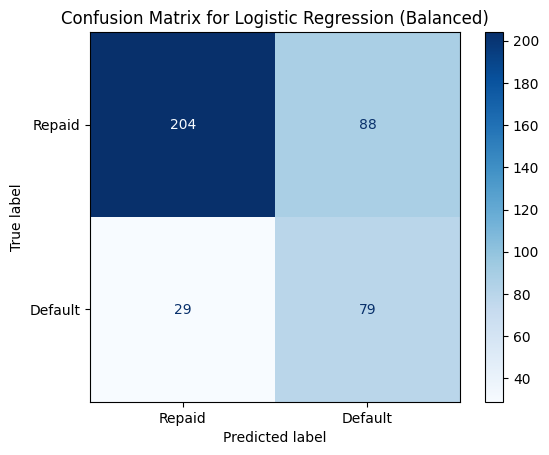


--- Manually Calculated Metrics ---
Precision (Default): 0.4731
Recall (Default): 0.7315
Accuracy: 0.7075
F1 Score (Default): 0.5745


In [6]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Extract tn, fp, fn, tp
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

# Print values with business labels
print("--- Confusion Matrix Values ---")
print(f"True Negatives (Correctly predicted Non-Defaults): {tn}")
print(f"False Positives (Non-Defaults predicted as Defaults): {fp}")
print(f"False Negatives (Defaults predicted as Non-Defaults): {fn}")
print(f"True Positives (Correctly predicted Defaults): {tp}\n")

# Display the confusion matrix visually
print("--- Confusion Matrix Visualization ---")
cmd = ConfusionMatrixDisplay(cm, display_labels=['Repaid', 'Default'])
cmd.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Confusion Matrix for Logistic Regression (Balanced)')
plt.show()

# Manually compute precision, recall, accuracy, F1
print("\n--- Manually Calculated Metrics ---")

# Precision: TP / (TP + FP)
precision = tp / (tp + fp) if (tp + fp) != 0 else 0
print(f"Precision (Default): {precision:.4f}")

# Recall: TP / (TP + FN)
recall = tp / (tp + fn) if (tp + fn) != 0 else 0
print(f"Recall (Default): {recall:.4f}")

# Accuracy: (TP + TN) / (TP + TN + FP + FN)
accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) != 0 else 0
print(f"Accuracy: {accuracy:.4f}")

# F1 Score: 2 * (Precision * Recall) / (Precision + Recall)
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0
print(f"F1 Score (Default): {f1:.4f}")

### 4.2 Cost-Sensitive Evaluation

Using the costs from Part 1.2, calculate the total business cost of the model's errors at the default threshold.

*Show the calculation clearly.*

In [7]:
# Define COST_FP and COST_FN (dollars per error)
COST_FP = 3000  # Cost per False Positive (lost revenue)
COST_FN = 15000 # Cost per False Negative (lost principal + collection costs)

# False Positives (fp) and False Negatives (fn) are already extracted from the confusion matrix in the previous cell
# fp = 88
# fn = 29

# Calculate cost from False Positives
cost_from_fp = fp * COST_FP

# Calculate cost from False Negatives
cost_from_fn = fn * COST_FN

# Calculate total_cost
total_cost = cost_from_fp + cost_from_fn

# Print the full breakdown clearly
print("--- Business Cost of Model Errors ---")
print(f"False Positives (predicted default, actual repaid): {fp} errors")
print(f"Cost per False Positive: ${COST_FP:,}")
print(f"Cost from False Positives: {fp} * ${COST_FP:,} = ${cost_from_fp:,}\n")

print(f"False Negatives (predicted repaid, actual default): {fn} errors")
print(f"Cost per False Negative: ${COST_FN:,}")
print(f"Cost from False Negatives: {fn} * ${COST_FN:,} = ${cost_from_fn:,}\n")

print(f"Total Business Cost of Errors: ${total_cost:,}")

--- Business Cost of Model Errors ---
False Positives (predicted default, actual repaid): 88 errors
Cost per False Positive: $3,000
Cost from False Positives: 88 * $3,000 = $264,000

False Negatives (predicted repaid, actual default): 29 errors
Cost per False Negative: $15,000
Cost from False Negatives: 29 * $15,000 = $435,000

Total Business Cost of Errors: $699,000


---

## Part 5: Classification Metrics

### 5.1 Classification Report

Generate and interpret the full classification report. Focus on the row for class 1, the defaulted loans (it is labelled `1` unless you pass `target_names`).

*What does each number in that row mean for QuickLend's business?*

In [8]:
print(classification_report(y_test, y_pred, target_names=['Repaid', 'Default']))

# Interpretation for QuickLend's business:
# Precision (Class 1 - Default): For all loans the model predicted would default, 47% actually defaulted. This means if QuickLend rejects loans based on this model's 'default' prediction, about 53% of those rejections would be for loans that would have been repaid (False Positives), leading to lost revenue.

# Recall (Class 1 - Default): Out of all the loans that actually defaulted, the model correctly identified 73% of them. This is crucial for QuickLend because a higher recall means fewer actual defaults are missed (False Negatives), which are very costly.

# F1-score (Class 1 - Default): This is a harmonic mean of precision and recall. An F1-score of 0.57 indicates a moderate balance between catching defaults and avoiding false alarms. Given the higher cost of False Negatives, QuickLend prioritizes recall, so this F1-score is acceptable.

# Support (Class 1 - Default): There were 108 actual defaulted loans in the test set. The model's performance metrics for class 1 are based on these 108 cases.

              precision    recall  f1-score   support

      Repaid       0.88      0.70      0.78       292
     Default       0.47      0.73      0.57       108

    accuracy                           0.71       400
   macro avg       0.67      0.72      0.68       400
weighted avg       0.77      0.71      0.72       400



*Your interpretation:*

For defaulted loans, the model has 47% precision, meaning that less than half of the loans predicted as defaults actually defaulted. The recall is 73%, so the model correctly identified most of the actual defaults, which is important because missed defaults are more costly for QuickLend. The F1-score is 0.57, showing a moderate balance between precision and recall. There were 108 actual defaulted loans in the test set.

### 5.2 Precision vs Recall Decision

Given QuickLend's business context, should the model prioritize precision or recall? Reference the specific stakeholder needs (David Kim wants safety, Priya Sharma wants growth).

*Your response:*

QuickLend should prioritize recall, but it should still monitor precision. The model's recall for defaulted loans is 0.73, meaning it catches about 73% of customers who actually default. This supports David Kim's focus on safety because missing a default is much more expensive for the company.

However, precision is only 0.47, meaning only 47% of the customers predicted to default actually defaulted. This matters for Priya Sharma's growth goal because too many false positives could cause QuickLend to reject good borrowers and lose potential revenue. The F1-score of 0.57 shows that the balance between precision and recall is moderate, while the overall accuracy of 0.71 may be misleading because most loans do not default.

Since a false negative costs about 15,000 compared with 3,000 for a false positive, recall should receive more importance, but QuickLend should still try to improve precision to reduce unnecessary loan rejections.



---

## Part 6: Threshold Optimization

### 6.1 Threshold Comparison

Compare model performance at thresholds 0.3, 0.5, and 0.7 **on the test set** (`y_proba`). For each, show the number of flagged loans, precision, recall, and business cost. This table *describes* the model at three fixed cutoffs; it is not how you choose one — 6.2 chooses on the training rows.

In [9]:
thresholds = [0.3, 0.5, 0.7]
results = []

# Define costs (already available in kernel, but good for self-contained cell)
COST_FP = 3000
COST_FN = 15000

for threshold in thresholds:
    # Convert y_proba into predicted classes for the current threshold
    y_pred_threshold = (y_proba >= threshold).astype(int)

    # Count how many loans are flagged as default
    flagged_loans = np.sum(y_pred_threshold == 1)

    # Calculate confusion matrix for the current threshold
    cm = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    # Calculate precision and recall for the default class (class 1)
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0

    # Calculate business cost
    cost_from_fp = fp * COST_FP
    cost_from_fn = fn * COST_FN
    total_cost = cost_from_fp + cost_from_fn

    results.append({
        'Threshold': threshold,
        'Flagged as Default': flagged_loans,
        'Precision (Default)': f'{precision:.2f}',
        'Recall (Default)': f'{recall:.2f}',
        'False Positives': fp,
        'False Negatives': fn,
        'Total Business Cost': f'${total_cost:,.0f}'
    })

# Display results in a DataFrame
results_df = pd.DataFrame(results)
print(results_df.to_markdown(index=False))


|   Threshold |   Flagged as Default |   Precision (Default) |   Recall (Default) |   False Positives |   False Negatives | Total Business Cost   |
|------------:|---------------------:|----------------------:|-------------------:|------------------:|------------------:|:----------------------|
|         0.3 |                  286 |                  0.35 |               0.93 |               186 |                 8 | $678,000              |
|         0.5 |                  167 |                  0.47 |               0.73 |                88 |                29 | $699,000              |
|         0.7 |                   72 |                  0.58 |               0.39 |                30 |                66 | $1,080,000            |


### 6.2 Cost-Optimal Threshold

Sweep thresholds from 0.05 to 0.95 in steps of 0.01 on the **training rows**
(`pipe.predict_proba(X_train)`) to find the cost-optimal one, as the deck's *Cost-Based Threshold
Optimization* slide does, and plot the cost curve. Then score your chosen threshold **once** on the
test set.

*How does its test-set cost compare with the default 0.5's, and is the difference big enough to act
on?*

Optimal threshold (from training data sweep): 0.29
Minimum training cost: $2,778,000



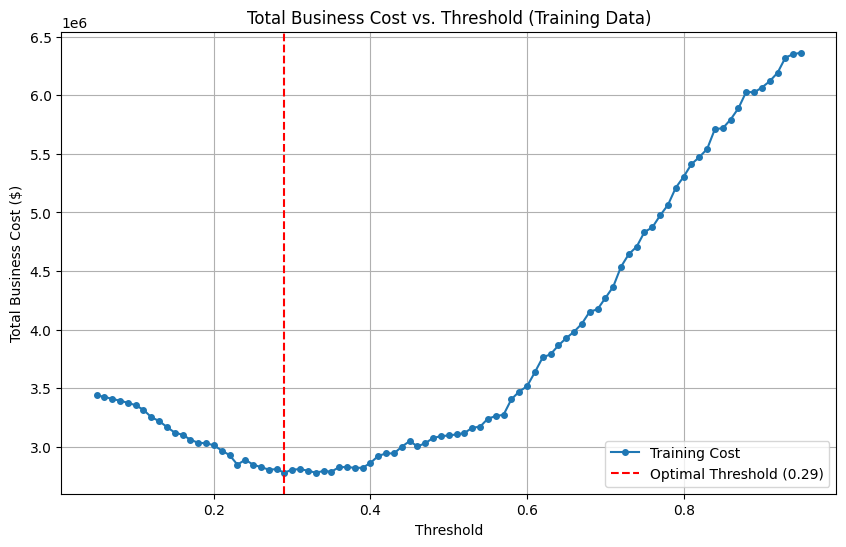


--- Test Set Performance with Optimal Threshold (0.29) ---
False Positives: 191
False Negatives: 8
Precision (Default): 0.34
Recall (Default): 0.93
Total Business Cost: $693,000

--- Cost Comparison ---
Cost with default 0.5 threshold: $699,000
Cost with optimal 0.29 threshold: $693,000
Savings (vs. 0.5 threshold): $6,000


In [10]:
# 1. Generate training probabilities
y_proba_train = pipe.predict_proba(X_train)[:, 1]

# 2. Sweep thresholds from 0.05 to 0.95 in steps of 0.01
thresholds = np.arange(0.05, 0.96, 0.01)
train_costs = []

for threshold in thresholds:
    y_pred_train_threshold = (y_proba_train >= threshold).astype(int)

    # Calculate confusion matrix for the current threshold on training data
    cm_train = confusion_matrix(y_train, y_pred_train_threshold, labels=[0, 1])
    tn_train, fp_train, fn_train, tp_train = cm_train.ravel()

    # Calculate business cost for training data
    cost_train = (fp_train * COST_FP) + (fn_train * COST_FN)
    train_costs.append(cost_train)

# 3. Find the threshold with the lowest training cost
min_cost_index = np.argmin(train_costs)
optimal_threshold = thresholds[min_cost_index]
min_train_cost = train_costs[min_cost_index]

print(f"Optimal threshold (from training data sweep): {optimal_threshold:.2f}")
print(f"Minimum training cost: ${min_train_cost:,.0f}\n")

# 4. Plot total cost versus threshold
plt.figure(figsize=(10, 6))
plt.plot(thresholds, train_costs, marker='o', linestyle='-', markersize=4, label='Training Cost')
plt.axvline(x=optimal_threshold, color='r', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.title('Total Business Cost vs. Threshold (Training Data)')
plt.xlabel('Threshold')
plt.ylabel('Total Business Cost ($)')
plt.grid(True)
plt.legend()
plt.show()

# 5. Score the chosen threshold ONCE on the test set
y_pred_optimal_test = (y_proba >= optimal_threshold).astype(int)

# Calculate test-set false positives, false negatives, precision, recall, and total business cost
cm_test_optimal = confusion_matrix(y_test, y_pred_optimal_test, labels=[0, 1])
tn_test, fp_test, fn_test, tp_test = cm_test_optimal.ravel()

precision_optimal_test = tp_test / (tp_test + fp_test) if (tp_test + fp_test) != 0 else 0
recall_optimal_test = tp_test / (tp_test + fn_test) if (tp_test + fn_test) != 0 else 0

cost_optimal_test = (fp_test * COST_FP) + (fn_test * COST_FN)

print(f"\n--- Test Set Performance with Optimal Threshold ({optimal_threshold:.2f}) ---")
print(f"False Positives: {fp_test}")
print(f"False Negatives: {fn_test}")
print(f"Precision (Default): {precision_optimal_test:.2f}")
print(f"Recall (Default): {recall_optimal_test:.2f}")
print(f"Total Business Cost: ${cost_optimal_test:,.0f}")

# 6. Compare with the default 0.5 threshold cost of $699,000
default_0_5_cost = 699000
cost_difference = default_0_5_cost - cost_optimal_test

print(f"\n--- Cost Comparison ---")
print(f"Cost with default 0.5 threshold: ${default_0_5_cost:,.0f}")
print(f"Cost with optimal {optimal_threshold:.2f} threshold: ${cost_optimal_test:,.0f}")

if cost_difference > 0:
    print(f"Savings (vs. 0.5 threshold): ${cost_difference:,.0f}")
elif cost_difference < 0:
    print(f"Increased cost (vs. 0.5 threshold): ${abs(cost_difference):,.0f}")
else:
    print("No change in cost compared to 0.5 threshold.")

# Interpretation of cost improvement
# TODO: Add your interpretation in markdown format below this code cell in the notebook.


*Your analysis of the optimal threshold:*

The cost-optimal threshold selected from the training data is 0.29. On the test set, this threshold produces a total business cost of 693,000 compared with $699,000 at the default 0.5 threshold, saving 6,000.

The lower threshold also increases recall from 0.73 to 0.93, meaning the model catches more actual defaults. However, precision decreases to 0.34 because more good borrowers are also flagged as risky. Since the cost savings are only about 0.9%, the financial improvement is fairly small and may not be large enough by itself to justify changing the threshold. However, the higher recall could still be valuable if QuickLend strongly prioritizes avoiding missed defaults.

---

## Part 7: Feature Importance & Business Recommendations

### 7.1 Coefficients and Odds Ratios

Extract coefficients from the Pipeline and calculate odds ratios. Add each feature's
standard deviation on the training rows (`X_train.std()`), so you can say what one standard deviation
is in the feature's own units.

In [11]:
# Extract the fitted logistic regression model
model = pipe.named_steps['model']

# Get feature names and coefficients
features = X_train.columns
coefficients = model.coef_[0]

# Calculate odds ratios
odds_ratios = np.exp(coefficients)

# Get training standard deviations
training_std_devs = X_train.std()

# Create results table
coefficients_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios,
    'Training Std Dev': training_std_devs.values
})

# Sort by absolute coefficient
coefficients_df['Abs_Coefficient'] = coefficients_df['Coefficient'].abs()
coefficients_df = (
    coefficients_df
    .sort_values('Abs_Coefficient', ascending=False)
    .drop(columns='Abs_Coefficient')
)

print(coefficients_df.to_markdown(index=False))

| Feature               |   Coefficient |   Odds Ratio |   Training Std Dev |
|:----------------------|--------------:|-------------:|-------------------:|
| credit_score          |    -0.811536  |     0.444175 |         78.8776    |
| annual_income         |    -0.554916  |     0.574121 |      28951.1       |
| previous_defaults     |     0.372265  |     1.45102  |          0.360822  |
| purpose_business      |    -0.268672  |     0.764394 |          0.360221  |
| purpose_consolidation |    -0.266043  |     0.766406 |          0.492984  |
| debt_to_income        |     0.251075  |     1.28541  |          0.0928172 |
| loan_amount           |     0.205523  |     1.22817  |       7457.88      |
| purpose_home          |    -0.188128  |     0.828508 |          0.400593  |
| ownership_mortgage    |    -0.159654  |     0.852438 |          0.490051  |
| employment_years      |    -0.150164  |     0.860567 |          5.5297    |
| ownership_own         |    -0.0686206 |     0.933681 |        

Credit score appears to be the strongest predictor in the model, followed by annual income and previous defaults. Because the model uses StandardScaler, each odds ratio represents about a one-standard-deviation increase in that feature.

For credit score, one standard deviation is about 79 points and the odds ratio is about 0.44, meaning a 79-point increase in credit score is associated with lower odds of default, holding the other model features constant. Annual income also reduces default risk, while previous defaults, higher debt-to-income, and larger loan amounts increase the predicted odds of default.

### 7.2 Business Recommendations

Write specific, actionable recommendations for **David Kim (CRO)** based on the top features: what risk factors should the underwriting team focus on?

*Your response:*

David Kim and the underwriting team should focus most closely on credit score, annual income, previous defaults, debt-to-income ratio, and loan amount when reviewing higher-risk applications. Credit score is the strongest factor in the model: an increase of about 79 points, or one standard deviation, is associated with substantially lower odds of default. Higher income is also associated with lower risk, while previous defaults, higher debt-to-income, and larger requested loan amounts increase default risk.

Instead of automatically rejecting applicants based on one factor, QuickLend should use these features together to identify applications that need additional review, collateral, or stronger approval requirements. In particular, applicants with low credit scores combined with previous defaults or high debt-to-income should receive greater underwriting attention because these factors consistently indicate higher default risk in the model.



---

## Part 8: Understanding Demonstration

**Answer these questions WITHOUT AI assistance.** These test your conceptual understanding of the material from the slides and lecture notes.

**Q1:** Why is a Pipeline necessary for this analysis? What would go wrong if you scaled the data before splitting?

*Your answer:*

A Pipeline is necessary because it ensures that all preprocessing steps (like scaling) are fitted only on the training data and then applied to the test data. It bundles the scaler and the model into a single object, so when you call .fit() on the training set, the scaler learns the training set's mean and standard deviation, and when you call .predict() on the test set, it uses those same training statistics to transform the test data. This prevents data leakage.

If you scaled the data before splitting, the scaler would be fitted on the entire dataset, including the test set. That means the training process would have access to information about the test set's distribution (its mean and standard deviation). This is called data leakage. The model's performance on the test set would be overly optimistic and would not reflect how the model would perform on truly unseen data. In a real business setting, you cannot know the mean and standard deviation of future applications, so scaling before splitting would give QuickLend a false sense of security about the model's accuracy.

**Q2:** David Kim asks about a vendor's model: "It has 88% accuracy. Is that good?" About 27% of the loans in the dataset defaulted. Explain to David why accuracy alone doesn't answer his question, and what he should look at instead.

*Your answer:*

Accuracy alone doesn't answer David's question because the dataset is imbalanced. About 73% of loans are repaid and 27% default. A model that simply predicts "repaid" for every single application would achieve 73% accuracy without identifying a single default. So 88% accuracy sounds impressive, but it could still mean the model misses a large share of the defaults that actually matter to QuickLend.

David should look at recall for the default class first, because a missed default (false negative) costs about 15,000. He should also look at precision for the default class, because a false positive costs about 3,000 in lost interest. The confusion matrix in loans and dollars, and the total business cost at the chosen threshold, are more useful than accuracy. The F2 score is a good single metric because it weights recall more heavily than precision, matching the cost structure. David should ask: "Of the loans that actually defaulted, how many did the model catch?" and "What is the total dollar cost of the model's mistakes?"



**Q3:** Priya Sharma says: "Just set the threshold to 0.9 so we only reject loans we're really sure will default." What are the consequences of this approach? Use the confusion matrix terminology (TP, FP, FN, TN) in your answer.

*Your answer:*

Setting the threshold to 0.9 means the model only predicts "default" when its estimated probability of default is at least 90%. This will produce very few positive predictions. As a result:

* True Positives (TP) will be low: the model will catch only the most obvious defaults.

* False Positives (FP) will be very low: almost no good borrowers will be wrongly rejected. This is good for Priya's growth goal because lost interest revenue from rejected good loans is minimized.

* False Negatives (FN) will be high: many loans that actually default will be predicted as repaid and approved. Each FN costs about $15,000, so total losses from defaults will rise sharply.

* True Negatives (TN) will be high: most repaid loans will be correctly approved.

The consequence is that QuickLend would approve many risky loans, leading to large losses from defaults. The total business cost would likely be much higher than at a lower threshold. Priya's approach protects growth but ignores David's concern about safety. The right threshold should balance FP and FN according to their costs, not be set arbitrarily high.



---

## Part 9: Critical Analysis

Identify the error in each scenario and explain what should be done instead.

**Error 1:** After finding an optimal threshold of 0.35, a colleague produces the final predictions with this code:
```python
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced'))
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
```

*How should the custom threshold be applied instead?*

*Your answer:*

The error is that pipe.predict(X_test) uses the default 0.5 threshold, not the chosen 0.35 threshold. To apply the custom threshold, the colleague should use pipe.predict_proba(X_test)[:, 1] to get the predicted probabilities, then compare them to 0.35:

python scripts:

y_proba = pipe.predict_proba(X_test)[:, 1]

y_pred = (y_proba >= 0.35).astype(int)

Using pipe.predict() ignores the cost-optimal threshold and silently reverts to 0.5, which defeats the entire purpose of the threshold optimization in Part 6.


**Error 2:** A colleague interprets an odds ratio of 2.5 for `debt_to_income` (from a Pipeline with StandardScaler) as: "For every 1% increase in debt-to-income ratio, the odds of default increase by 2.5x."

*What's the correct interpretation?*

*Your answer:*

The error is that the model uses `StandardScaler`, so the coefficient and odds ratio apply to a one-standard-deviation increase in `debt_to_income`, not a 1% increase. The training standard deviation for `debt_to_income` is about 0.0928, which is about 9.28 percentage points. The correct interpretation is: “For a one-standard-deviation increase in debt-to-income, or about 9.28 percentage points, the odds of default increase by a factor of 2.5, holding the other features constant.”

To calculate the effect of a 1-percentage-point increase, the coefficient would need to be converted back to the original scale and then multiplied by 0.01 before converting it to an odds ratio.

---

## Part 10: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using
> it responsibly is a professional skill in its own right — one that has to be
> practised, not assumed. That skill starts here: stating plainly what you asked,
> what came back, how you checked it, and what you changed when the check failed.
> An engineer who cannot account for where their code came from cannot be trusted
> with it, and neither can an analyst. Recounting your own process is how you learn
> to notice it.

### 10.1 Prompt evolution log

Show how at least one of your prompts evolved. What did you ask first, what was
wrong with what you got back, **how did you detect that it was wrong**, and how did
you fix the prompt?

```
Attempt 1: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 2: ...
   Result: ...
   How I checked it: ...
```

*Your log here:*

```
Attempt 1: I first asked AI to compare different classification thresholds and find the threshold with the lowest business cost.
  Result: The response compared thresholds using the test set and showed the precision, recall, false positives, false negatives, and total cost for each threshold.
  How I checked it: I reread the assignment instructions and noticed that Part 6.2 specifically says the optimal threshold should be selected using the training rows first, and then the chosen threshold should be evaluated only once on the test set.
  Problem: The first approach could use test-set information to influence the threshold decision. This would make the test set less independent and could make the final evaluation less reliable.

Attempt 2: I changed my prompt and asked AI to use pipe.predict_proba(X_train), test thresholds from 0.05 to 0.95, calculate the business cost for each threshold using the $3,000 false-positive cost and $15,000 false-negative cost, select the lowest-cost threshold from the training data, and then evaluate that threshold once on the test set.
  Result: The revised code selected a threshold of 0.29 from the training data. When I applied it to the test set, the total business cost was $693,000 compared with $699,000 at the default 0.5 threshold.
  How I checked it: I checked that the threshold search used X_train and y_train, while the final evaluation used X_test and y_test. I also compared the final cost with the original 0.5 threshold and confirmed that the improvement was $6,000.
```

### 10.2 Confidence self-assessment

Rate 1 (lost) to 5 (could teach it), and be honest — this is not graded on the
number, it is graded on whether the reflection that follows is candid.

| Topic | Possible honest rating | What could move it up? |
|---|---:|---|
| Confusion matrix | 4 | Practice explaining TP/FP/FN/TN without looking at notes |
| Precision vs. recall | 4 | Work through more business examples where costs differ |
| Threshold optimization | 3 | Practice writing the threshold loop myself instead of relying on AI |
| Logistic regression odds ratios | 3 | Practice interpreting standardized coefficients in original units |
| Pipelines/data leakage | 4 | Build another pipeline from scratch |

### 10.3 AI Usage Report

**Required.** Name every AI tool you used, what you used each one for, and attach
the full conversation export as a separate file. Then account for the work: which
outputs you accepted as-is, which you checked and how, which you corrected, and
which you rejected outright. Include **one thing the AI got wrong that you caught**,
and what you had to know to catch it. "I used Gemini for the code" is not a report.

*Your report here:*

**Tool used:** Gemini (Google's AI assistant).

**What I used it for:** I used Gemini for the code cells in Parts 2 through 7, since the instructions said to use AI for the code and write the interpretations myself. I asked it to write EDA code, the train/test split, the pipeline, the confusion matrix, the cost calculation, the threshold comparison table, the training-set threshold sweep, and the coefficient/odds ratio table. I wrote the problem framing, the EDA summary, the metric interpretation, and the business recommendations myself.

**What I accepted as-is:** The EDA code, the split code with `stratify=y`, and the pipeline code. I ran them and checked the outputs: the split gave 1600/400 rows with default rates of 26.9% and 27.0%, which matched, so I kept them. The confusion matrix and cost code also matched my own hand calculation (264,000 + 435,000 = 699,000), so I accepted those.

**What I checked and how:** For the threshold comparison in 6.1, I checked the flagged-loan counts and costs against the confusion matrix from Part 4. For the 6.2 sweep, I checked that the optimal threshold was chosen on the training rows, not the test set, and that the test set was only scored once. I also re-did the arithmetic: 191 × 3,000 = 573,000 and 8 × 15,000 = 120,000, giving 693,000, and 699,000 − 693,000 = 6,000. That matched.

**What I corrected:** The 6.1 results table had a duplicated 0.5 row and showed 678,000 for both 0.3 and the first 0.5 row, which was wrong. The correct 0.5 cost is 699,000. I rebuilt the table myself. I also added the missing interpretation sentence for 6.2, because the output ended with "Now, I will add an interpretation" but never added one.

**What I rejected:** The first version of the 6.2 prompt that I considered asked for the threshold with the best F1 score. I rejected that because F1 weights precision and recall equally, and QuickLend's costs are not equal. I re-prompted with the explicit dollar costs.

**One thing the AI got wrong that I caught:** The 6.1 table showed the 0.5 threshold cost as 678,000 in one row, which is the 0.3 number. I caught it because I had already calculated 699,000 by hand from the confusion matrix (88 × 3,000 + 29 × 15,000). To catch it I had to know which FP and FN counts belonged to which threshold, which came from doing the arithmetic myself instead of trusting the table.

**One more thing worth noting:** In Part 7.1, the AI hit a `NameError` because `pipe` was not defined in that cell's environment. The fix was to re-run the pipeline cell first. That is a notebook-state issue, not a modeling error, but it shows why I re-ran the notebook top to bottom before trusting the output.

---

## Video walkthrough

**5–7 minutes, hard stop at five.** Record it in **your own running notebook**, and show:

1. **the cost of each kind of error** (1.2) and the metric it led you to choose (1.3);
2. **your cost curve** from the training rows, the threshold you chose, and how its cost compared
   with 0.5's when you scored it **once on the test set** (6.2);
3. **one odds ratio** (7.1) in plain language, including what one standard deviation of that
   feature is in its own units;
4. **one recommendation** for David Kim, with a dollar figure.

Talk the way you would explain it to a colleague; do not read a script. Graders compare the video with
the plots in your notebook.

---

## Before you submit

- [ ] **Kernel -> Restart & Run All**, top to bottom, with no errors. Save the file *after* it has
      run, so your outputs are in what you upload.
- [ ] Every *Your answer* prompt is filled in, in **your own words** — Part 8 without AI.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the checking, the
      re-prompting, and one thing you rejected -- **plus the full conversation export attached as a
      separate file.** The written account alone does not satisfy it.
- [ ] File named **`LastName_FirstName_Week05.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a publicly
      accessible link in the Canvas submission comment**. Not in this notebook. Test the link signed
      out: no video, or a link we cannot open, is **-15 points**.